In [ ]:
%pip -q install tensorflow-datasets importlib-resources

In [ ]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

SEED = 42
tf.keras.utils.set_random_seed(SEED)

IMG_SIZE = 128
NUM_CLASSES = 3
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0
GPU devices: []


In [ ]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "oxford_iiit_pet",
    split=["train[:90%]", "train[90%:]", "test"],
    with_info=True,
    as_supervised=False
)

print(info)
print("Training examples:", tf.data.experimental.cardinality(train_raw).numpy())
print("Validation examples:", tf.data.experimental.cardinality(val_raw).numpy())
print("Test examples:", tf.data.experimental.cardinality(test_raw).numpy())

tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='/root/tensorflow_datasets/oxford_iiit_pet/4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text(shape=(), dtype=string),
        'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'label': ClassLab

In [ ]:
def preprocess(example):
    image = tf.image.resize(
        example["image"],
        (IMG_SIZE, IMG_SIZE),
        method="bilinear"
    )
    image = tf.cast(image, tf.float32) / 255.0

    mask = tf.image.resize(
        example["segmentation_mask"],
        (IMG_SIZE, IMG_SIZE),
        method="nearest"
    )
    mask = tf.cast(mask, tf.int32) - 1
    mask = tf.squeeze(mask, axis=-1)

    return image, mask


def make_dataset(raw_dataset, training=False):
    dataset = raw_dataset.map(preprocess, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.shuffle(512, seed=SEED)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(train_raw, training=True)
val_ds = make_dataset(val_raw)
test_ds = make_dataset(test_raw)

for images, masks in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Mask batch shape:", masks.shape)
    print("Unique mask classes:", np.unique(masks.numpy()))

Image batch shape: (16, 128, 128, 3)
Mask batch shape: (16, 128, 128)
Unique mask classes: [0 1 2]


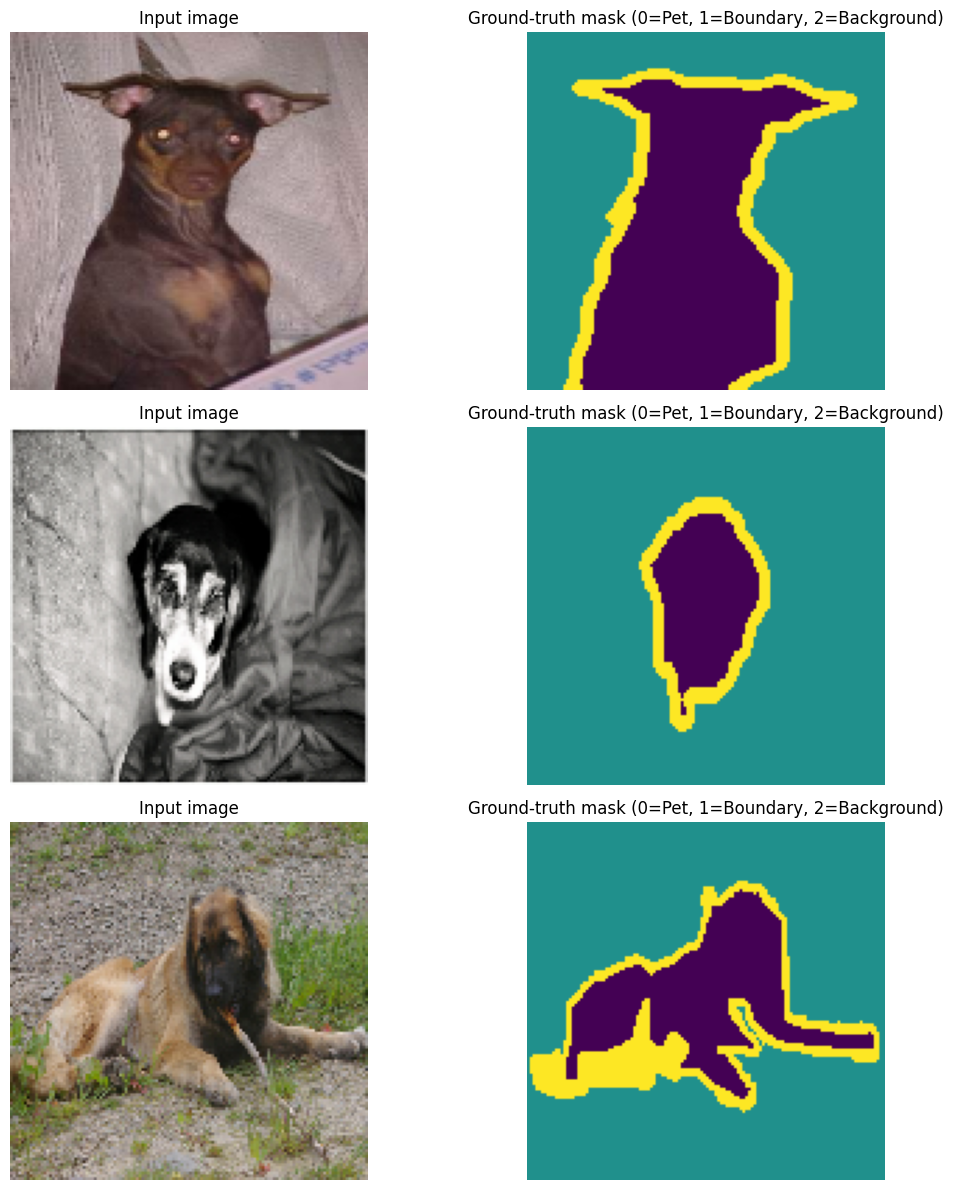

In [ ]:
CLASS_NAMES = ["Pet", "Boundary", "Background"]

def show_samples(dataset, count=3):
    images, masks = next(iter(dataset))
    count = min(count, images.shape[0])

    plt.figure(figsize=(12, 4 * count))
    for i in range(count):
        plt.subplot(count, 2, 2 * i + 1)
        plt.imshow(images[i].numpy())
        plt.title("Input image")
        plt.axis("off")

        plt.subplot(count, 2, 2 * i + 2)
        plt.imshow(masks[i].numpy(), vmin=0, vmax=2, cmap="viridis")
        plt.title("Ground-truth mask (0=Pet, 1=Boundary, 2=Background)")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(train_ds)

In [ ]:
def conv_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    return x


def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    inputs = tf.keras.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = tf.keras.layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = tf.keras.layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = tf.keras.layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256)
    p4 = tf.keras.layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck
    c5 = conv_block(p4, 512)

    # Decoder with skip connections
    u6 = tf.keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(c5)
    u6 = tf.keras.layers.Concatenate()([u6, c4])
    c6 = conv_block(u6, 256)

    u7 = tf.keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(c6)
    u7 = tf.keras.layers.Concatenate()([u7, c3])
    c7 = conv_block(u7, 128)

    u8 = tf.keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c7)
    u8 = tf.keras.layers.Concatenate()([u8, c2])
    c8 = conv_block(u8, 64)

    u9 = tf.keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c8)
    u9 = tf.keras.layers.Concatenate()([u9, c1])
    c9 = conv_block(u9, 32)

    outputs = tf.keras.layers.Conv2D(
        num_classes, 1, activation="softmax"
    )(c9)

    return tf.keras.Model(inputs, outputs, name="U_Net")


model = build_unet()
model.summary()

Model: "U_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 128, 128,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 64, 64,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_6[

 Total params: 7,771,939 (29.65 MB)

 Trainable params: 7,766,051 (29.63 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [ ]:
class ArgmaxMeanIoU(tf.keras.metrics.MeanIoU):
    def __init__(self, num_classes, name="mean_iou", dtype=None):
        super().__init__(num_classes=num_classes, name=name, dtype=dtype)

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_pred = tf.math.argmax(y_pred, axis=-1)
        return super().update_state(y_true, y_pred, sample_weight)

mean_iou_metric = ArgmaxMeanIoU(
    num_classes=NUM_CLASSES,
    name="mean_iou"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "sparse_categorical_accuracy",
        mean_iou_metric
    ]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

EPOCHS = 15
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

training_time = time.time() - start_time
print(f"Training time: {training_time / 60:.2f} minutes")

Epoch 1/15
120/207 ━━━━━━━━━━━━━━━━━━━━ 13:39 9s/step - loss: 0.8987 - mean_iou: 0.3763 - sparse_categorical_accuracy: 0.6243

In [ ]:
def plot_training_history(history):
    metrics = [
        ("loss", "Loss"),
        ("sparse_categorical_accuracy", "Pixel accuracy"),
        ("mean_iou", "Mean IoU")
    ]

    plt.figure(figsize=(15, 4))
    for i, (key, title) in enumerate(metrics, 1):
        plt.subplot(1, 3, i)
        plt.plot(history.history[key], label="Training")
        plt.plot(history.history["val_" + key], label="Validation")
        plt.title(title)
        plt.xlabel("Epoch")
        plt.legend()
        plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_history(history)

In [ ]:
def visualize_predictions(dataset, count=4):
    images, true_masks = next(iter(dataset))
    probabilities = model.predict(images[:count], verbose=0)
    predicted_masks = np.argmax(probabilities, axis=-1)

    n = min(count, images.shape[0])
    plt.figure(figsize=(15, 4 * n))

    for i in range(n):
        plt.subplot(n, 3, 3 * i + 1)
        plt.imshow(images[i].numpy())
        plt.title("Input image")
        plt.axis("off")

        plt.subplot(n, 3, 3 * i + 2)
        plt.imshow(true_masks[i].numpy(), vmin=0, vmax=2, cmap="viridis")
        plt.title("Ground truth")
        plt.axis("off")

        plt.subplot(n, 3, 3 * i + 3)
        plt.imshow(predicted_masks[i], vmin=0, vmax=2, cmap="viridis")
        plt.title("U-Net prediction")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(test_ds, count=4)

In [ ]:
def evaluate_segmentation(model, dataset, num_classes=NUM_CLASSES):
    confusion = np.zeros((num_classes, num_classes), dtype=np.int64)

    for images, true_masks in dataset:
        probabilities = model.predict(images, verbose=0)
        pred_masks = np.argmax(probabilities, axis=-1)

        y_true = true_masks.numpy().reshape(-1)
        y_pred = pred_masks.reshape(-1)

        batch_confusion = tf.math.confusion_matrix(
            y_true,
            y_pred,
            num_classes=num_classes
        ).numpy()
        confusion += batch_confusion

    true_positive = np.diag(confusion).astype(np.float64)
    actual = confusion.sum(axis=1).astype(np.float64)
    predicted = confusion.sum(axis=0).astype(np.float64)

    union = actual + predicted - true_positive
    iou_per_class = np.divide(
        true_positive, union,
        out=np.zeros_like(true_positive),
        where=union != 0
    )

    dice_denominator = actual + predicted
    dice_per_class = np.divide(
        2 * true_positive, dice_denominator,
        out=np.zeros_like(true_positive),
        where=dice_denominator != 0
    )

    pixel_accuracy = true_positive.sum() / max(confusion.sum(), 1)

    return {
        "confusion_matrix": confusion,
        "iou_per_class": iou_per_class,
        "dice_per_class": dice_per_class,
        "mean_iou": iou_per_class.mean(),
        "mean_dice": dice_per_class.mean(),
        "pixel_accuracy": pixel_accuracy
    }


results = evaluate_segmentation(model, test_ds)

print("Confusion matrix (rows=true, columns=predicted):")
print(results["confusion_matrix"])

print("\nPer-class metrics:")
for i, name in enumerate(CLASS_NAMES):
    print(
        f"{name:12s} | IoU: {results['iou_per_class'][i]:.4f}"
        f" | Dice: {results['dice_per_class'][i]:.4f}"
    )

print(f"\nMean IoU:        {results['mean_iou']:.4f}")
print(f"Mean Dice:       {results['mean_dice']:.4f}")
print(f"Pixel Accuracy:  {results['pixel_accuracy']:.4f}")

In [ ]:
x = np.arange(NUM_CLASSES)
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, results["iou_per_class"], width, label="IoU")
plt.bar(x + width / 2, results["dice_per_class"], width, label="Dice")
plt.xticks(x, CLASS_NAMES)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Per-class segmentation performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
model.save("oxford_pet_unet.keras")
print("Model saved as oxford_pet_unet.keras")